# Descriptive stats for all columns

In [16]:
import matplotlib as plt
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

### Load the Data

In [17]:
RAW = "../data/raw"
df = pd.read_csv(f"{RAW}/diabetic_data.csv")
variables = pd.read_csv(f"{RAW}/variables.csv")

df.shape

C:\Users\piedu\AppData\Local\Temp\ipykernel_24996\3568291170.py:2: DtypeWarning: Columns (10: payer_code) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(f"{RAW}/diabetic_data.csv")


(101766, 50)

Output Directory

In [18]:
out = Path("../reports/figures")
out.mkdir(parents=True, exist_ok=True)

#### View of Numerical data

In [19]:
df.describe()

,encounter_id,patient_nbr,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,1.017660e+05,1.017660e+05,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,1.652016e+08,5.433040e+07,2.024006,3.715642,5.754437,4.395987,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566,7.422607
std,1.026403e+08,3.869636e+07,1.445403,5.280166,4.064081,2.985108,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863,1.933600
min,1.252200e+04,1.350000e+02,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,8.496119e+07,2.341322e+07,1.000000,1.000000,1.000000,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000
50%,1.523890e+08,4.550514e+07,1.000000,1.000000,7.000000,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000,8.000000
75%,2.302709e+08,8.754595e+07,3.000000,4.000000,7.000000,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000,9.000000
max,4.438672e+08,1.895026e+08,8.000000,28.000000,25.000000,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000,16.000000


#### View of Categorical data

In [20]:
for col in df.select_dtypes("object"):
    if col in df.columns:
        print(col)

race
gender
age
weight
payer_code
medical_specialty
diag_1
diag_2
diag_3
max_glu_serum
A1Cresult
metformin
repaglinide
nateglinide
chlorpropamide
glimepiride
acetohexamide
glipizide
glyburide
tolbutamide
pioglitazone
rosiglitazone
acarbose
miglitol
troglitazone
tolazamide
examide
citoglipton
insulin
glyburide-metformin
glipizide-metformin
glimepiride-pioglitazone
metformin-rosiglitazone
metformin-pioglitazone
change
diabetesMed
readmitted


C:\Users\piedu\AppData\Local\Temp\ipykernel_24996\3997384342.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes("object"):


Unique Value Counts

In [21]:
for col in df.select_dtypes("object"):
    print(f"{df[col].value_counts(dropna=False)}\n")

C:\Users\piedu\AppData\Local\Temp\ipykernel_24996\4195830634.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes("object"):


race
Caucasian          76099
AfricanAmerican    19210
NaN                 2273
Hispanic            2037
Other               1506
Asian                641
Name: count, dtype: int64

gender
Female             54708
Male               47055
Unknown/Invalid        3
Name: count, dtype: int64

age
[70-80)     26068
[60-70)     22483
[50-60)     17256
[80-90)     17197
[40-50)      9685
[30-40)      3775
[90-100)     2793
[20-30)      1657
[10-20)       691
[0-10)        161
Name: count, dtype: int64

weight
NaN          98569
[75-100)      1336
[50-75)        897
[100-125)      625
[125-150)      145
[25-50)         97
[0-25)          48
[150-175)       35
[175-200)       11
>200             3
Name: count, dtype: int64

payer_code
NaN    40256
MC     32439
HM      6274
SP      5007
BC      4655
MD      3532
CP      2533
UN      2448
CM      1937
OG      1033
PO       592
DM       549
CH       146
WC       135
OT        95
MP        79
SI        55
FR         1
Name: count, dtype: int64

me

Number of Categorical vs Numerical Columns

In [22]:
num_cols = df.select_dtypes(include="number").columns
cat_cols = df.select_dtypes(exclude="number").columns

print(f"Numeric columns: {len(num_cols)}")
print(f"Categorical columns: {len(cat_cols)}")
print(f"Total: {df.shape[1]}")

Numeric columns: 13
Categorical columns: 37
Total: 50


### Amount of patients who repeat encounter

In [23]:
visits = df["patient_nbr"].value_counts()

print(f"Patients: {len(visits):,}")
print(f"Patients with 2+ encounters: {(visits > 1).sum():,} ({(visits > 1).mean():.1%})")
print(f"Encounters from repeat patients: {visits[visits > 1].sum():,} ({visits[visits > 1].sum() / len(df):.1%})")


Patients: 71,518
Patients with 2+ encounters: 16,773 (23.5%)
Encounters from repeat patients: 47,021 (46.2%)


### Encounters that cannot be readmitted

`discharge_disposition_id` includes codes for patients who died in hospital or were discharged to hospice. These encounters can never show a 30-day readmission, so keeping them would bias the target toward "NO". The expired codes have zero readmissions, which confirms the logic. Hospice codes show a few readmissions but are also dropped in the original study. These rows will be removed in preprocessing.

In [24]:
# IDS_mapping: 11, 19, 20, 21 = Expired; 13, 14 = Hospice
# These patients cannot be readmitted, so standard practice (Strack et al. 2014) is to drop them.
not_readmittable = [11, 13, 14, 19, 20, 21]
mask = df["discharge_disposition_id"].isin(not_readmittable)

print(f"Expired/hospice encounters: {mask.sum():,} ({mask.mean():.1%} of rows)")
print()
print(df[mask].groupby("discharge_disposition_id")["readmitted"].value_counts().unstack(fill_value=0))


Expired/hospice encounters: 2,423 (2.4% of rows)

readmitted                <30  >30    NO
discharge_disposition_id                
11                          0    0  1642
13                         19   36   344
14                         24    7   341
19                          0    0     8
20                          0    0     2


## Three-Class Readmitted Split

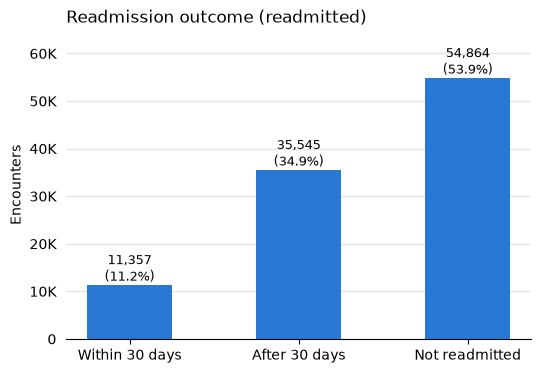

In [25]:
# Count each class in a meaningful order (not sorted by size)
order = ["<30", ">30", "NO"]
counts = df["readmitted"].value_counts().reindex(order)
pct = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["Within 30 days", "After 30 days", "Not readmitted"], counts,
              width=0.5, color="#2a78d6")

# Count + percentage on top of each bar
for bar, n, p in zip(bars, counts, pct):
    ax.text(bar.get_x() + bar.get_width() / 2, n, f"{n:,}\n({p:.1f}%)",
            ha="center", va="bottom", fontsize=9)

ax.set_title("Readmission outcome (readmitted)", loc="left")
ax.set_ylabel("Encounters")
ax.yaxis.set_major_formatter(lambda y, _: f"{y/1000:.0f}K" if y else "0")
ax.set_ylim(0, counts.max() * 1.18)       
ax.grid(axis="y", color="#e5e5e2", linewidth=1)
ax.set_axisbelow(True)                   
ax.tick_params(left=False)

for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)

fig.savefig(out / "readmitted_split.png", dpi=200, bbox_inches="tight")
plt.show()


## Column Missing-ness Number

In [26]:
missing_num = []

for col in df.columns:
    n_nan = df[col].isna().sum()
    if n_nan:
        missing_num.append([col, n_nan])
        print(f"{col}: {n_nan} NaN,({n_nan / len(df):.1%})")


race: 2273 NaN,(2.2%)
weight: 98569 NaN,(96.9%)
payer_code: 40256 NaN,(39.6%)
medical_specialty: 49949 NaN,(49.1%)
diag_1: 21 NaN,(0.0%)
diag_2: 358 NaN,(0.4%)
diag_3: 1423 NaN,(1.4%)
max_glu_serum: 96420 NaN,(94.7%)
A1Cresult: 84748 NaN,(83.3%)


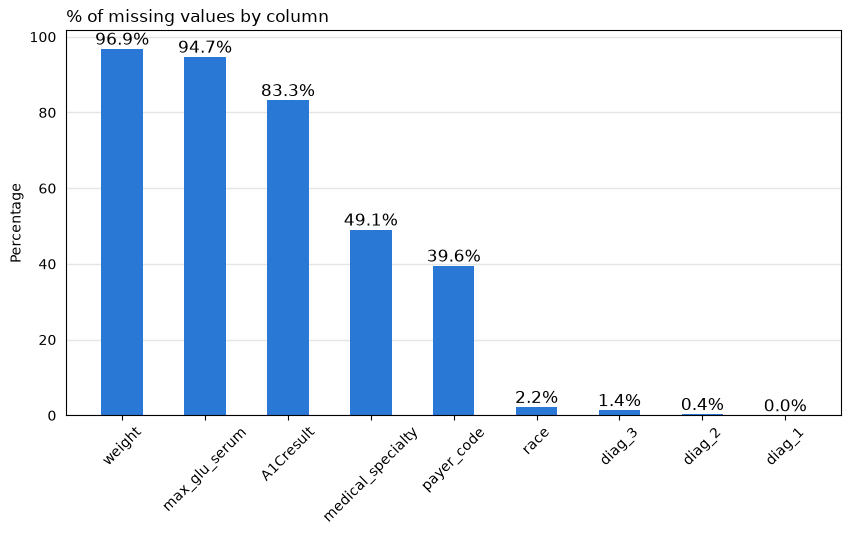

In [27]:
fig, ax = plt.subplots(figsize=(10, 5))

missing_num = sorted(missing_num, key=lambda x: x[1], reverse=True)

cols = [col for col, _ in missing_num]
pct = [num / len(df) * 100 for _, num in missing_num]
bars = ax.bar(cols, pct, width=0.5, color="#2a78d6")
ax.bar_label(bars, labels=[f"{p:.1f}%" for p in pct], fontsize=12)

ax.set_title("% of missing values by column", loc="left")
ax.set_ylabel("Percentage")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", color="#e5e5e2", linewidth=1)
ax.set_axisbelow(True)
ax.tick_params(left=False)

plt.show()


Columns over 50% missing values

In [28]:
def read_info(col):
    print(f"{df[col].dropna().sample(3)}")    
    print(f"{"-"*20}")

for col in cols:
    read_info(col)

62218    [150-175)
20307     [75-100)
88716      [50-75)
Name: weight, dtype: str
--------------------
30745    Norm
20600    >200
18470    >200
Name: max_glu_serum, dtype: str
--------------------
25461    >8
77396    >8
15393    >8
Name: A1Cresult, dtype: str
--------------------
24867                Psychiatry
48190    Family/GeneralPractice
29892               Pulmonology
Name: medical_specialty, dtype: str
--------------------
39179    MC
70588    BC
85484    SP
Name: payer_code, dtype: str
--------------------
54544    Caucasian
44159    Caucasian
5222         Other
Name: race, dtype: str
--------------------
10345    696
25983    428
27937    493
Name: diag_3, dtype: str
--------------------
39372       425
20506       788
78688    250.42
Name: diag_2, dtype: str
--------------------
94994    486
38637    599
52837    518
Name: diag_1, dtype: str
--------------------


## Drug Status column plots against Readmission

Text(0, 0.5, 'Count')

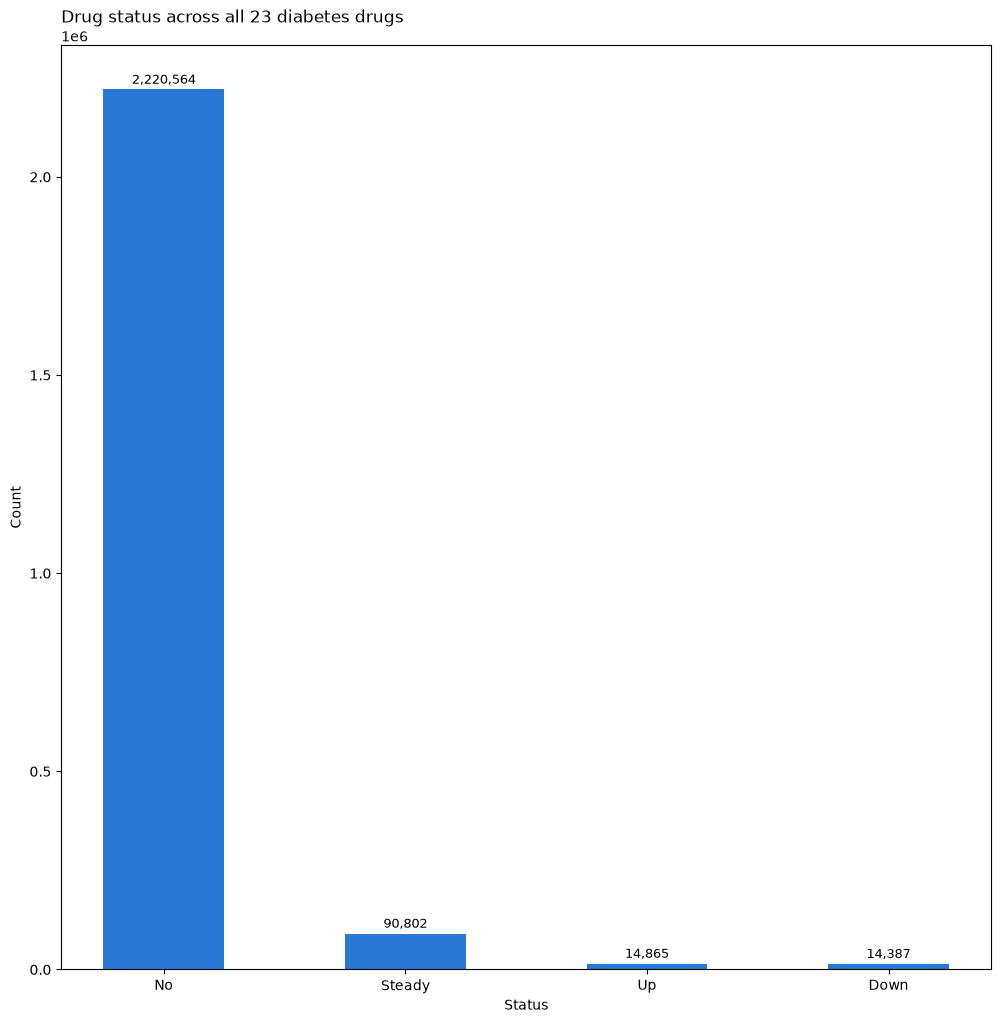

In [29]:
drug_predictors = ["metformin",
"repaglinide",
"nateglinide",
"chlorpropamide",
"glimepiride",
"acetohexamide",
"glipizide",
"glyburide",
"tolbutamide",
"pioglitazone",
"rosiglitazone",
"acarbose",
"miglitol",
"troglitazone",
"tolazamide",
"examide",
"citoglipton",
"insulin",
"glyburide-metformin",
"glipizide-metformin",
"glimepiride-pioglitazone",
"metformin-rosiglitazone",
"metformin-pioglitazone",
]

status_totals  = df[drug_predictors].melt()["value"].value_counts()

fig, ax = plt.subplots(figsize=(12, 12))

bars = ax.bar(status_totals.index, status_totals, width=0.5, color="#2a78d6")
ax.bar_label(bars, labels=[f"{n:,}" for n in status_totals], fontsize=9, padding=2)

ax.set_title("Drug status across all 23 diabetes drugs", loc="left")
ax.set_xlabel("Status")                        # x-axis label
ax.set_ylabel("Count")                         # y-axis label



Which values each drug contains

In [30]:
n_status = df[drug_predictors].nunique()

print("Number of drugs cols that don't have all 4 statuses")
print(f"{len(n_status[n_status < 4])}/{len(drug_predictors)}\n")

for drug in n_status[n_status < 4].index:
    print(drug, sorted(df[drug].unique()))



Number of drugs cols that don't have all 4 statuses
10/23

acetohexamide ['No', 'Steady']
tolbutamide ['No', 'Steady']
troglitazone ['No', 'Steady']
tolazamide ['No', 'Steady', 'Up']
examide ['No']
citoglipton ['No']
glipizide-metformin ['No', 'Steady']
glimepiride-pioglitazone ['No', 'Steady']
metformin-rosiglitazone ['No', 'Steady']
metformin-pioglitazone ['No', 'Steady']


Imbalance for No-to-NonNo drug statuses

In [31]:
non_no = (df[drug_predictors] != "No").sum().sort_values(ascending=True)
print(non_no.to_string())

examide                         0
citoglipton                     0
glimepiride-pioglitazone        1
acetohexamide                   1
metformin-pioglitazone          1
metformin-rosiglitazone         2
troglitazone                    3
glipizide-metformin            13
tolbutamide                    23
miglitol                       38
tolazamide                     39
chlorpropamide                 86
acarbose                      308
nateglinide                   703
glyburide-metformin           706
repaglinide                  1539
glimepiride                  5191
rosiglitazone                6365
pioglitazone                 7328
glyburide                   10650
glipizide                   12686
metformin                   19988
insulin                     54383


In [32]:
first_visit = df.drop_duplicates("patient_nbr")
multi = (first_visit[drug_predictors] != "No").sum(axis=1) >= 2
print(f"Patients on 2+ drugs at first encounter: {multi.sum():,} ({multi.mean():.1%})")


Patients on 2+ drugs at first encounter: 22,375 (31.3%)


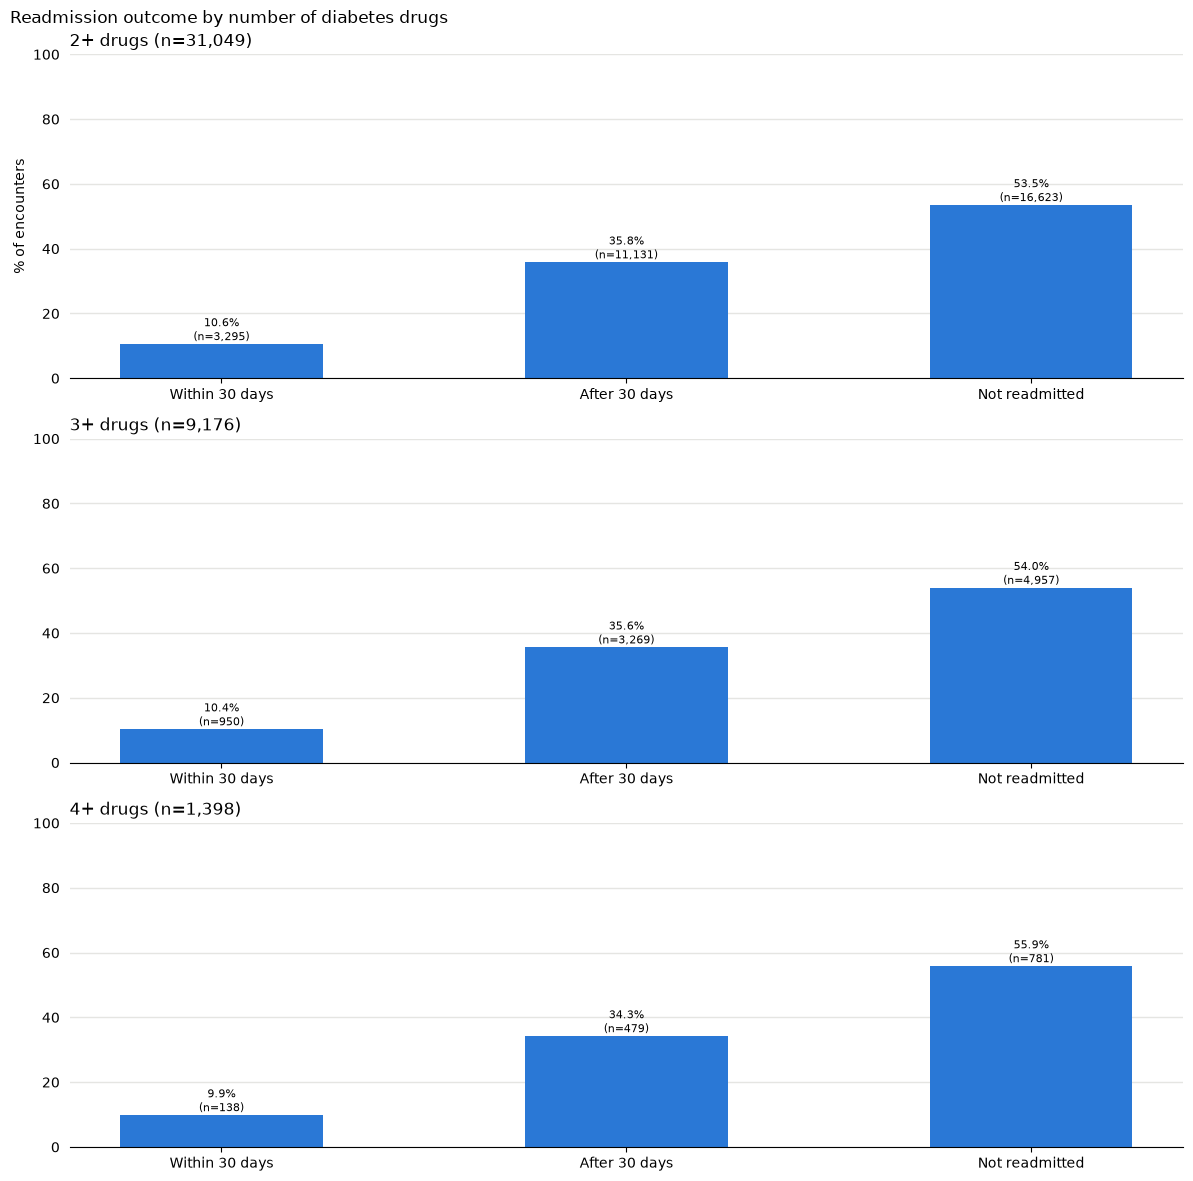

In [33]:
drugs_per_row = (df[drug_predictors] != "No").sum(axis=1)
order = ["<30", ">30", "NO"]
labels = ["Within 30 days", "After 30 days", "Not readmitted"]
thresholds = [2, 3, 4]

fig, axes = plt.subplots(3, 1, figsize=(12, 12), sharey=True)

for ax, k in zip(axes, thresholds):
    sub = df[drugs_per_row >= k]
    counts = sub["readmitted"].value_counts().reindex(order)
    pct = counts / counts.sum() * 100

    bars = ax.bar(labels, pct, width=0.5, color="#2a78d6")
    for bar, n, p in zip(bars, counts, pct):
        ax.text(bar.get_x() + bar.get_width() / 2, p, f"{p:.1f}%\n(n={n:,})",
                ha="center", va="bottom", fontsize=8)

    ax.set_title(f"{k}+ drugs (n={len(sub):,})", loc="left")
    ax.grid(axis="y", color="#e5e5e2", linewidth=1)
    ax.set_axisbelow(True)
    ax.tick_params(left=False)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)

axes[0].set_ylabel("% of encounters")
axes[0].set_ylim(0, 100)
fig.suptitle("Readmission outcome by number of diabetes drugs", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(out / "readmitted_by_drug_count.png", dpi=200, bbox_inches="tight")
plt.show()


### Readmission rate by key Cat Columns

In [34]:
key_cols = ["age", "race", "gender", "admission_type_id", "diabetesMed", "change", "insulin"]
key_out = Path("../reports/figures/key_cols")
key_out.mkdir(parents=True, exist_ok=True)

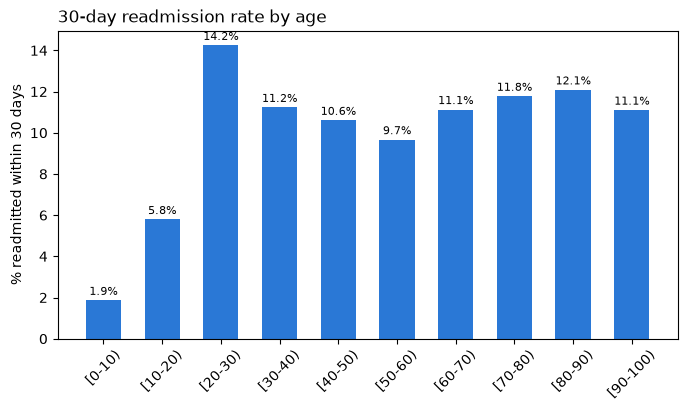

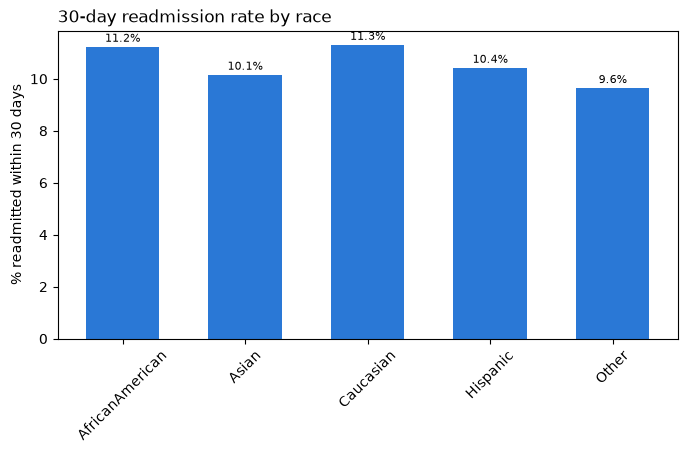

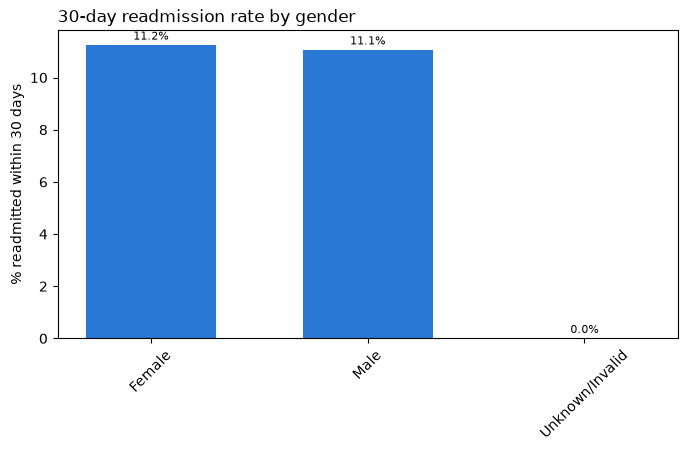

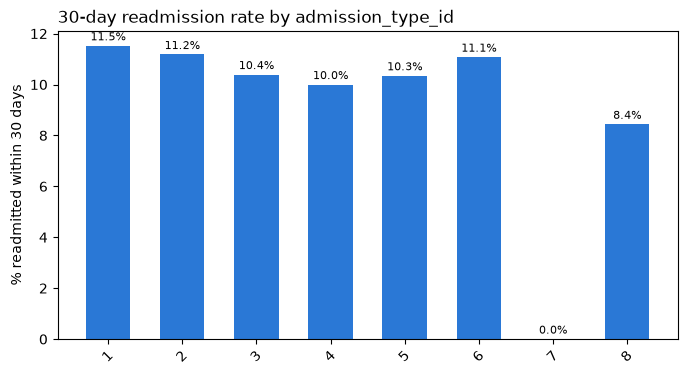

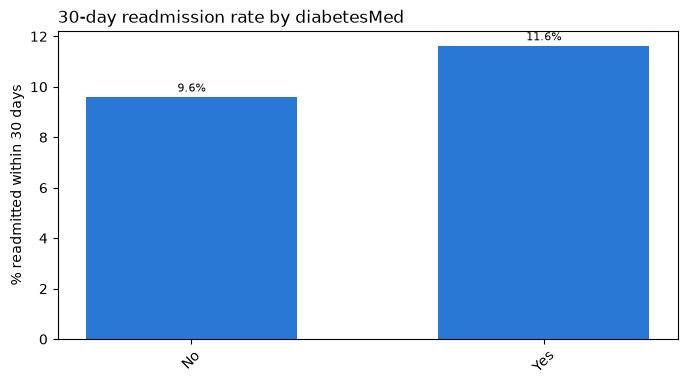

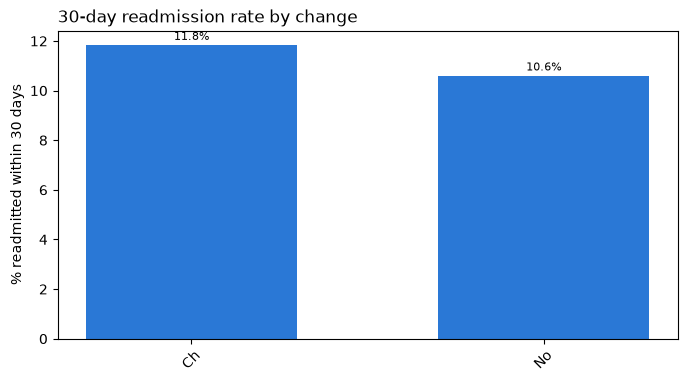

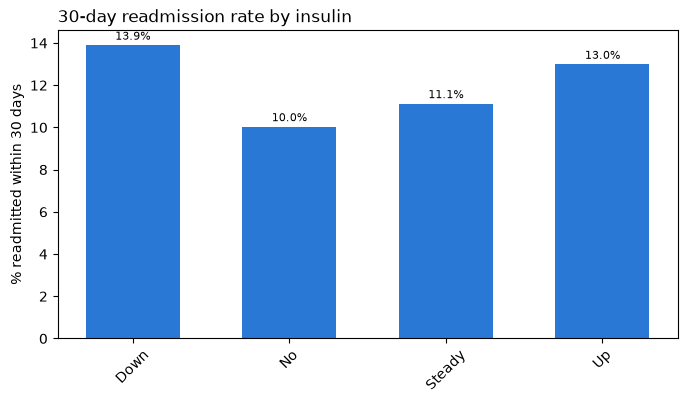

In [35]:
df["readmit_30"] = (df["readmitted"] == "<30").astype(int)

for col in key_cols:
    rate = df.groupby(col)["readmit_30"].mean() * 100

    fig, ax = plt.subplots(figsize=(8, 4))
    bars = ax.bar(rate.index.astype(str), rate, width=0.6, color="#2a78d6")
    ax.bar_label(bars, labels=[f"{p:.1f}%" for p in rate], fontsize=8, padding=2)
    ax.set_title(f"30-day readmission rate by {col}", loc="left")
    ax.set_ylabel("% readmitted within 30 days")
    ax.tick_params(axis="x", rotation=45)

    fig.savefig(out / f"key_cols/{col}.png", dpi=200, bbox_inches="tight")
    plt.show()




## Readmission of Payer and specialty
Both columns are about 40-50% blank and have many rare levels 


In [36]:
def rate_table(col):
    s = df[col].fillna("Missing")
    t = df.groupby(s)["readmit_30"].agg(n="size", readmit_30="mean")
    t.insert(1, "pct_rows", t["n"] / len(df))
    return t.sort_values("n", ascending=False)

fmt = {"pct_rows": "{:.1%}".format, "readmit_30": "{:.1%}".format}

print(rate_table("payer_code").to_string(formatters=fmt))


                n pct_rows readmit_30
payer_code                           
Missing     40256    39.6%      11.5%
MC          32439    31.9%      11.7%
HM           6274     6.2%      10.3%
SP           5007     4.9%      10.2%
BC           4655     4.6%       9.2%
MD           3532     3.5%      11.8%
CP           2533     2.5%       8.4%
UN           2448     2.4%       9.3%
CM           1937     1.9%      10.2%
OG           1033     1.0%      13.2%
PO            592     0.6%       7.4%
DM            549     0.5%      11.7%
CH            146     0.1%       8.9%
WC            135     0.1%       3.7%
OT             95     0.1%       7.4%
MP             79     0.1%      11.4%
SI             55     0.1%      12.7%
FR              1     0.0%       0.0%


Top 15 specialties 

In [48]:
spec = rate_table("medical_specialty")
print(spec.head(15).to_string(formatters=fmt))

                                     n pct_rows readmit_30
medical_specialty                                         
Missing                          49949    49.1%      11.6%
InternalMedicine                 14635    14.4%      11.2%
Emergency/Trauma                  7565     7.4%      11.2%
Family/GeneralPractice            7440     7.3%      11.9%
Cardiology                        5352     5.3%       7.9%
Surgery-General                   3099     3.0%      11.0%
Nephrology                        1613     1.6%      15.4%
Orthopedics                       1400     1.4%      10.8%
Orthopedics-Reconstructive        1233     1.2%       7.5%
Radiologist                       1140     1.1%       9.0%
Pulmonology                        871     0.9%      11.0%
Psychiatry                         854     0.8%      12.2%
Urology                            685     0.7%       9.9%
ObstetricsandGynecology            671     0.7%       4.8%
Surgery-Cardiovascular/Thoracic    652     0.6%       6.

How much the top 10 cover

In [49]:
counts = spec["n"]
print(f"{len(counts)} levels, top 10 cover {counts.head(10).sum() / len(df):.1%} of rows, "
      f"{(counts < 100).sum()} levels have under 100 rows")


73 levels, top 10 cover 91.8% of rows, 44 levels have under 100 rows


In [50]:
for col in ["payer_code", "medical_specialty"]:
    r = df.groupby(df[col].isna())["readmit_30"].mean()
    print(f"{col:18s} recorded: {r[False]:.1%}   missing: {r[True]:.1%}")


payer_code         recorded: 10.9%   missing: 11.5%
medical_specialty  recorded: 10.8%   missing: 11.6%


## Categorical Summary Table 

In [37]:
visits = df["patient_nbr"].value_counts()
drugs_per_row = (df[drug_predictors] != "No").sum(axis=1)
readmit_30 = (df["readmitted"] == "<30")

summary = pd.DataFrame([
    ["Encounters",                     f"{len(df):,}"],
    ["Distinct patients",              f"{len(visits):,}"],
    ["Patients with 2+ encounters",    f"{(visits > 1).sum():,} ({(visits > 1).mean():.1%})"],
    ["Columns (numeric / categorical)", f"{df.shape[1]} ({len(num_cols)} / {len(cat_cols)})"],
    ["Columns with >50% missing",      ", ".join(c for c, n in missing_num if n / len(df) > 0.5)],
    ["Readmitted <30 days",            f"{readmit_30.sum():,} ({readmit_30.mean():.1%})"],
    ["Readmitted >30 days",            f"{(df['readmitted'] == '>30').sum():,} ({(df['readmitted'] == '>30').mean():.1%})"],
    ["Not readmitted",                 f"{(df['readmitted'] == 'NO').sum():,} ({(df['readmitted'] == 'NO').mean():.1%})"],
    ["Encounters on 2+ diabetes drugs", f"{(drugs_per_row >= 2).sum():,} ({(drugs_per_row >= 2).mean():.1%})"],
    ["Drugs never prescribed",         ", ".join(n_status[n_status == 1].index)],
], columns=["Metric", "Value"])

summary


,Metric,Value
0,Encounters,"101,766"
1,Distinct patients,"71,518"
2,Patients with 2+ encounters,"16,773 (23.5%)"
3,Columns (numeric / categorical),51 (13 / 37)
4,Columns with >50% missing,"weight, max_glu_serum, A1Cresult"
5,Readmitted <30 days,"11,357 (11.2%)"
6,Readmitted >30 days,"35,545 (34.9%)"
7,Not readmitted,"54,864 (53.9%)"
8,Encounters on 2+ diabetes drugs,"31,049 (30.5%)"
9,Drugs never prescribed,"examide, citoglipton"


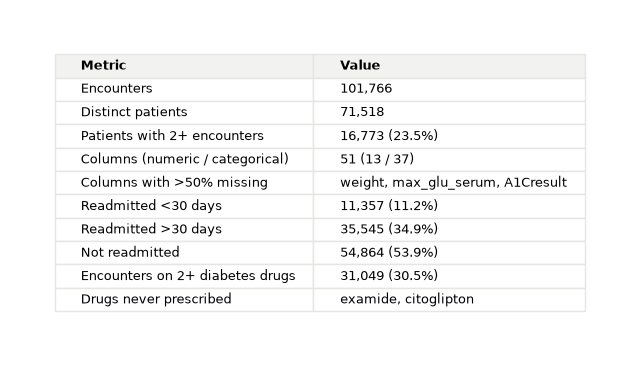

In [38]:
summary.to_csv(out / "eda_summary.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 0.4 * len(summary) + 0.5))
ax.axis("off")
tbl = ax.table(cellText=summary.values, colLabels=summary.columns,
               cellLoc="left", colLoc="left", loc="center")
tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
tbl.scale(1, 1.4)
tbl.auto_set_column_width([0, 1])
for (r, c), cell in tbl.get_celld().items():
    cell.set_edgecolor("#e5e5e2")
    if r == 0:
        cell.set_text_props(weight="bold")
        cell.set_facecolor("#f2f2f0")
fig.savefig(out / "eda_summary.png", dpi=200, bbox_inches="tight")
plt.show()


## Numeric Columns against target

In [39]:
visit_cols = ["number_inpatient", "number_emergency", "number_outpatient",]


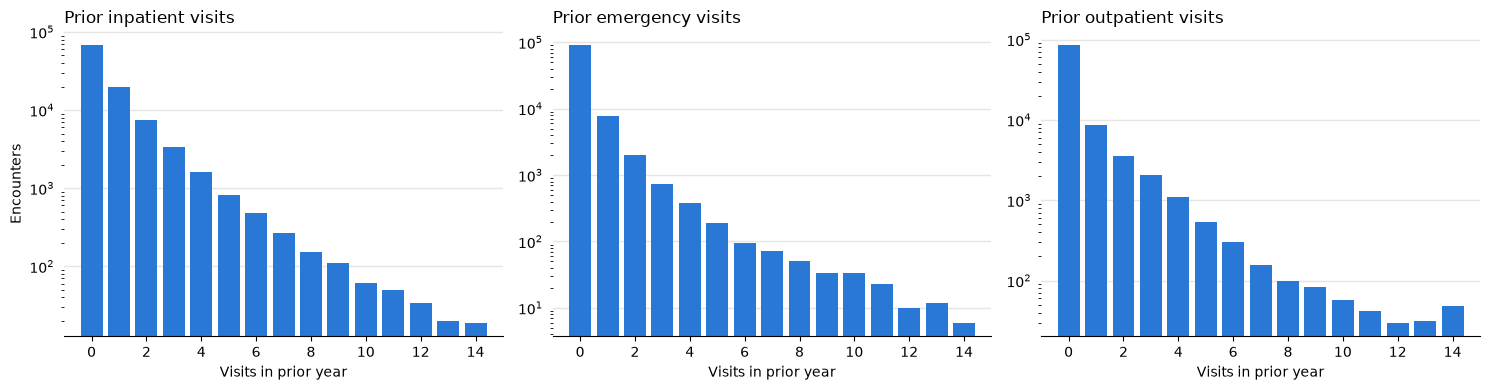

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, visit_cols):
    data = df[col]                                  # raw column, one value per encounter
    ax.hist(data, bins=range(0, 16), color="#2a78d6", align="left", rwidth=0.8)
    ax.set_title(col.replace("number_", "Prior ") + " visits", loc="left")
    ax.set_xlabel("Visits in prior year")
    ax.set_yscale("log")
    ax.set_xlim(-1, 15)
    ax.grid(axis="y", color="#e5e5e2", linewidth=1)
    ax.set_axisbelow(True)
    ax.tick_params(left=False)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)

axes[0].set_ylabel("Encounters")
fig.tight_layout()
fig.savefig(out / "prior_visits_hist.png", dpi=200, bbox_inches="tight")
plt.show()

Readmission rate for 30< days 

In [41]:
for col in visit_cols:
    binned = df[col].clip(upper=10) if col.startswith("number_") else pd.qcut(df[col], 5, duplicates="drop")
    print(df.groupby(binned, observed=True)["readmit_30"].agg(rate="mean", n="size").assign(rate=lambda s: (s.rate * 100).round(1)), "\n")


                  rate      n
number_inpatient             
0                  8.4  67630
1                 12.9  19521
2                 17.4   7566
3                 20.3   3411
4                 23.6   1622
5                 31.4    812
6                 34.6    480
7                 35.4    268
8                 44.4    151
9                 42.3    111
10                53.6    194 

                  rate      n
number_emergency             
0                 10.5  90383
1                 14.4   7677
2                 18.3   2042
3                 20.3    725
4                 30.7    374
5                 24.5    192
6                 23.4     94
7                 26.0     73
8                 32.0     50
9                 36.4     33
10                30.1    123 

                   rate      n
number_outpatient             
0                  10.7  85027
1                  13.9   8547
2                  13.7   3594
3                  12.3   2042
4                  15.1   1099

clip(upper=5) caps the values. Any number above 10 becomes 10. Numbers at or below 10 stay as they are. 

a patient with 12 prior inpatient visits is treated as having 10. So then when grouped by that column, you get 11 groups:
0, 1, 2, ..., 10 or more"

This is because few patients have 10+, prior visits so if left as separate groups, each one has a handful of rows and its readmission rate is noise

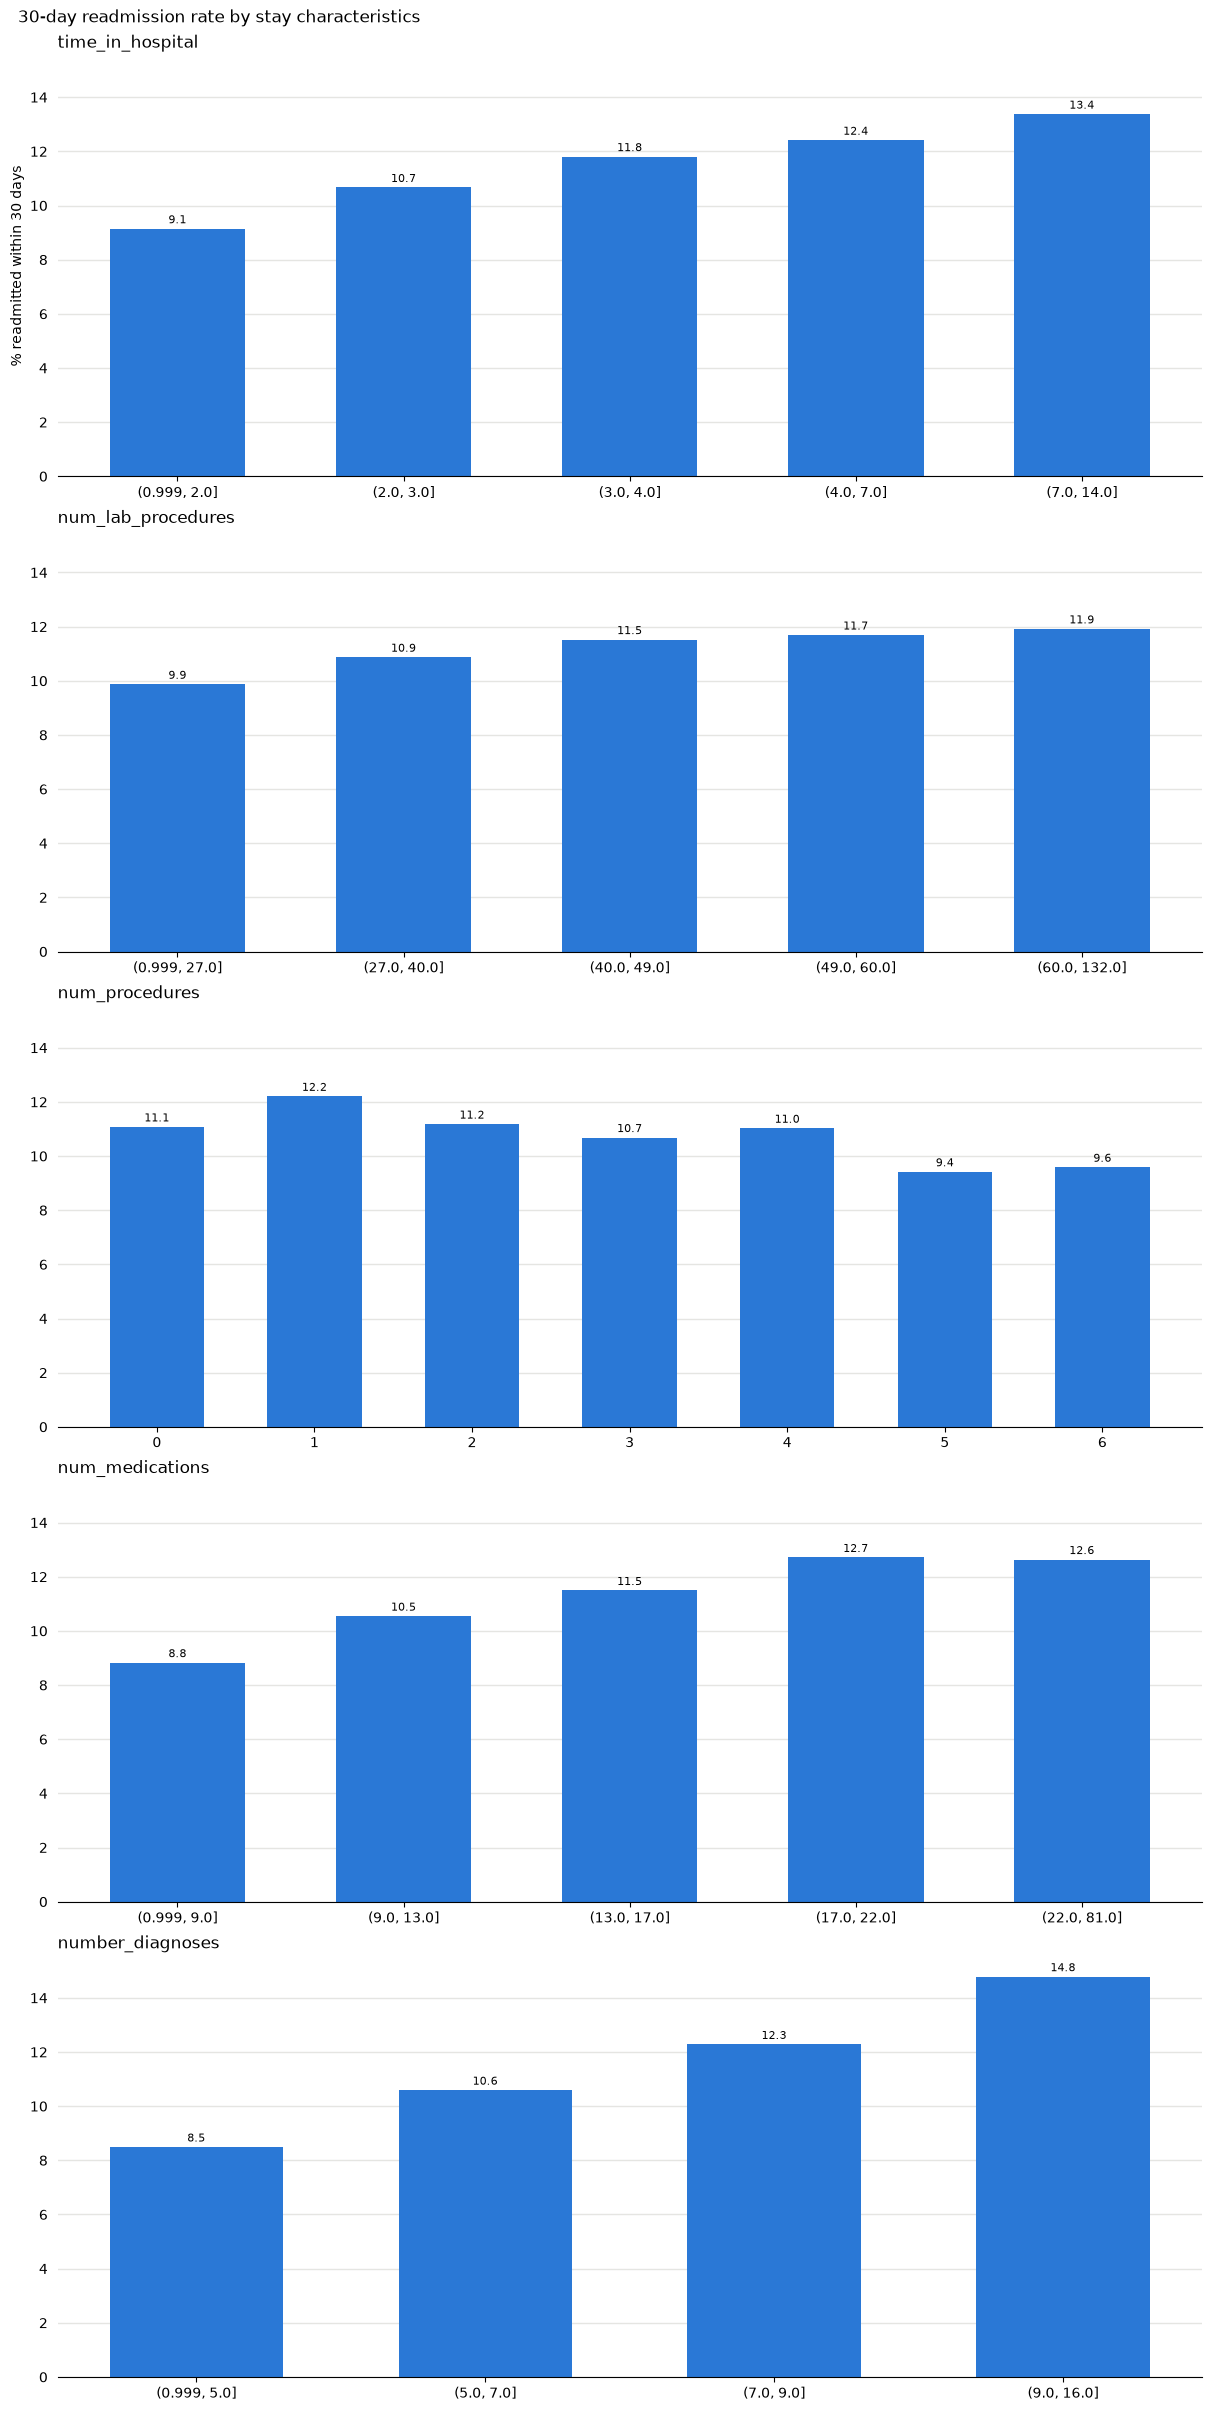

In [42]:
situation_cols = ["time_in_hospital", "num_lab_procedures", "num_procedures",
             "num_medications", "number_diagnoses"]
overall = df["readmit_30"].mean() * 100

fig, axes = plt.subplots(5, 1, figsize=(12, 24),
                         sharey=True, layout="constrained")

for ax, col in zip(axes, situation_cols):
    if df[col].nunique() <= 10:
        binned = df[col]                                   # few values: keep as is
    else:
        binned = pd.qcut(df[col], 5, duplicates="drop")    # many values: 5 equal-size bins
    g = df.groupby(binned, observed=True)["readmit_30"].agg(rate="mean", n="size")
    g["rate"] *= 100

    bars = ax.bar(g.index.astype(str), g["rate"], width=0.6, color="#2a78d6")
    ax.bar_label(bars, labels=[f"{r:.1f}" for r in g["rate"]], fontsize=8, padding=2)
    ax.set_title(col, loc="left")
    ax.grid(axis="y", color="#e5e5e2", linewidth=1)
    ax.set_axisbelow(True)
    ax.tick_params(left=False)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)

axes[0].set_ylabel("% readmitted within 30 days")
fig.suptitle("30-day readmission rate by stay characteristics", x=0.01, ha="left")
fig.savefig(out / "readmit_rate_stay_cols.png", dpi=200, bbox_inches="tight")
plt.show()


### Encounters that cannot be readmitted

`discharge_disposition_id` includes codes for patients who died in hospital or were discharged to hospice. These encounters can never show a 30-day readmission, so keeping them would bias the target. Expired codes have zero readmissions, Hospice codes show a few readmissions but are also dropped in the original study


In [43]:
# IDS_mapping: 11, 19, 20, 21 = Expired; 13, 14 = Hospice
not_readmittable = [11, 13, 14, 19, 20, 21]
mask = df["discharge_disposition_id"].isin(not_readmittable)

print(f"Expired/hospice encounters: {mask.sum():,} ({mask.mean():.1%} of rows)")
print()
print(df[mask].groupby("discharge_disposition_id")["readmitted"].value_counts().unstack(fill_value=0))


Expired/hospice encounters: 2,423 (2.4% of rows)

readmitted                <30  >30    NO
discharge_disposition_id                
11                          0    0  1642
13                         19   36   344
14                         24    7   341
19                          0    0     8
20                          0    0     2


## ID code columns

In [44]:
id_cols = ["admission_type_id", "discharge_disposition_id", "admission_source_id"]

for col in id_cols:
    summary = (df.groupby(col)["readmitted"]
                 .agg(n="size",
                      pct_rows=lambda s: len(s) / len(df),
                      readmit_30=lambda s: (s == "<30").mean())
                 .sort_values("n", ascending=False))
    print(f"{col} ({len(summary)} codes)")
    print(summary.to_string(formatters={"pct_rows": "{:.1%}".format,
                                        "readmit_30": "{:.1%}".format}), "\n")


admission_type_id (8 codes)
                       n pct_rows readmit_30
admission_type_id                           
1                  53990    53.1%      11.5%
3                  18869    18.5%      10.4%
2                  18480    18.2%      11.2%
6                   5291     5.2%      11.1%
5                   4785     4.7%      10.3%
8                    320     0.3%       8.4%
7                     21     0.0%       0.0%
4                     10     0.0%      10.0% 

discharge_disposition_id (26 codes)
                              n pct_rows readmit_30
discharge_disposition_id                           
1                         60234    59.2%       9.3%
3                         13954    13.7%      14.7%
6                         12902    12.7%      12.7%
18                         3691     3.6%      12.4%
2                          2128     2.1%      16.1%
22                         1993     2.0%      27.7%
11                         1642     1.6%       0.0%
5               

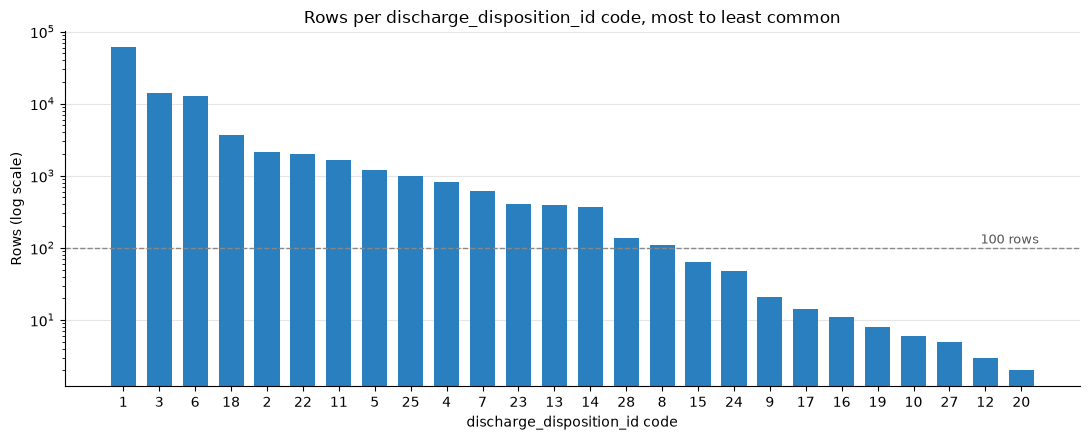

In [45]:
import matplotlib.pyplot as plt

counts = df["discharge_disposition_id"].value_counts() 

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(range(len(counts)), counts.values, width=0.7, color="#2a7fbf")
ax.set_xticks(range(len(counts)), counts.index.astype(str))
ax.set_yscale("log")

ax.axhline(100, color="#888", linestyle="--", linewidth=1)
ax.text(len(counts) - 0.5, 115, "100 rows", ha="right", color="#555", fontsize=9)

ax.set_title("Rows per discharge_disposition_id code, most to least common")
ax.set_xlabel("discharge_disposition_id code")
ax.set_ylabel("Rows (log scale)")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()


### Grouping the ID codes by meaning

There's a problem with the raw codes where most of the discharge codes and 17 source codes appear in fewer than 100 rows, so their readmission rates are noise. 

Each code goes into a larger group that shares a clinical meaning, defined in `data/id_groups.py`. These groups
were determined by an LLM as we don't have the medical knowledge to properly choose the groups ourselves. 

- **admission_type**
- **admission_source** 
- **discharge_disposition**

In [46]:
import sys
sys.path.insert(0, "..")
from scripts.id_groups import apply_id_groups, ID_GROUPS

grouped = apply_id_groups(df[~df["discharge_disposition_id"].isin(not_readmittable)])

for id_col, (col, _) in ID_GROUPS.items():
    summary = (grouped.groupby(col)["readmit_30"]
                      .agg(n="size",
                           pct_rows=lambda s: len(s) / len(grouped),
                           readmit_30="mean")
                      .sort_values("n", ascending=False))
    print(f"{col} ({len(summary)} groups, was {df[id_col].nunique()} codes)")
    print(summary.to_string(formatters={"pct_rows": "{:.1%}".format,
                                        "readmit_30": "{:.1%}".format}), "\n")

admission_type (4 groups, was 8 codes)
                    n pct_rows readmit_30
admission_type                           
Emergency       52389    52.7%      11.8%
Elective        18668    18.8%      10.5%
Urgent          18132    18.3%      11.4%
Unknown         10154    10.2%      10.9% 

admission_source (4 groups, was 17 codes)
                      n pct_rows readmit_30
admission_source                           
Emergency Room    55850    56.2%      12.0%
Referral          30434    30.6%      10.7%
Unknown            6874     6.9%      10.8%
Transfer           6185     6.2%      10.1% 

discharge_disposition (7 groups, was 26 codes)
                           n pct_rows readmit_30
discharge_disposition                           
Home                   60234    60.6%       9.3%
Nursing facility       14817    14.9%      14.6%
Home with care         13010    13.1%      12.7%
Unknown                 4708     4.7%      11.7%
Rehab/LTC/Psych         3791     3.8%      24.0%
Hospital 